In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# 解决中文/显示警告
plt.rcParams["figure.figsize"] = (12,6)

# 读取清洗好的part2数据
df = pd.read_csv("dataset_part_2.csv")
df.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


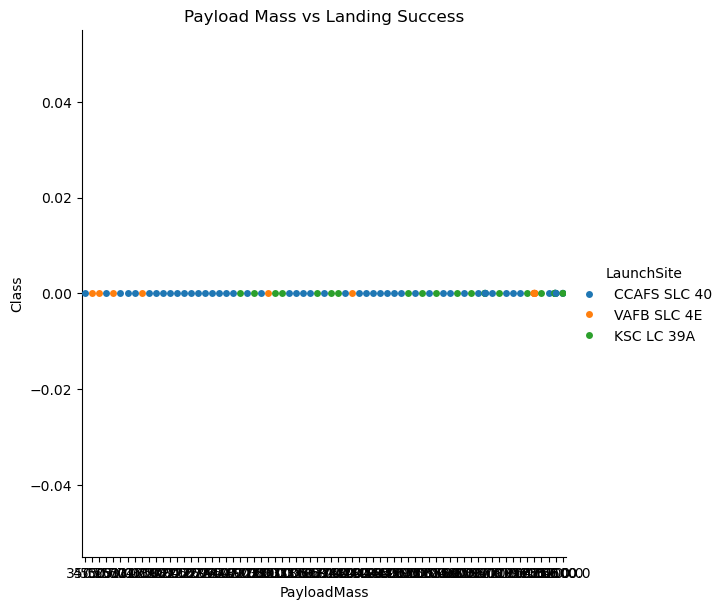

In [2]:
# 载荷质量 和 回收结果散点图，按发射站点区分
sns.catplot(x="PayloadMass", y="Class", hue="LaunchSite", data=df, height=6)
plt.title("Payload Mass vs Landing Success")
plt.show()

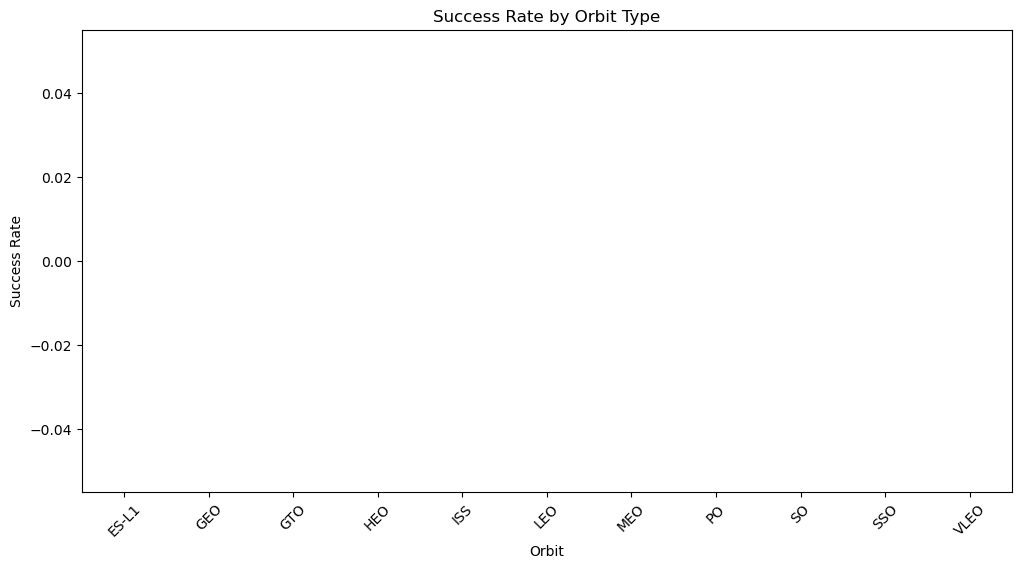

In [3]:
# 不同轨道类型的平均成功率柱状图
orbit_success = df.groupby("Orbit")['Class'].mean().reset_index()
sns.barplot(x="Orbit", y="Class", data=orbit_success)
plt.xticks(rotation=45)
plt.ylabel("Success Rate")
plt.title("Success Rate by Orbit Type")
plt.show()

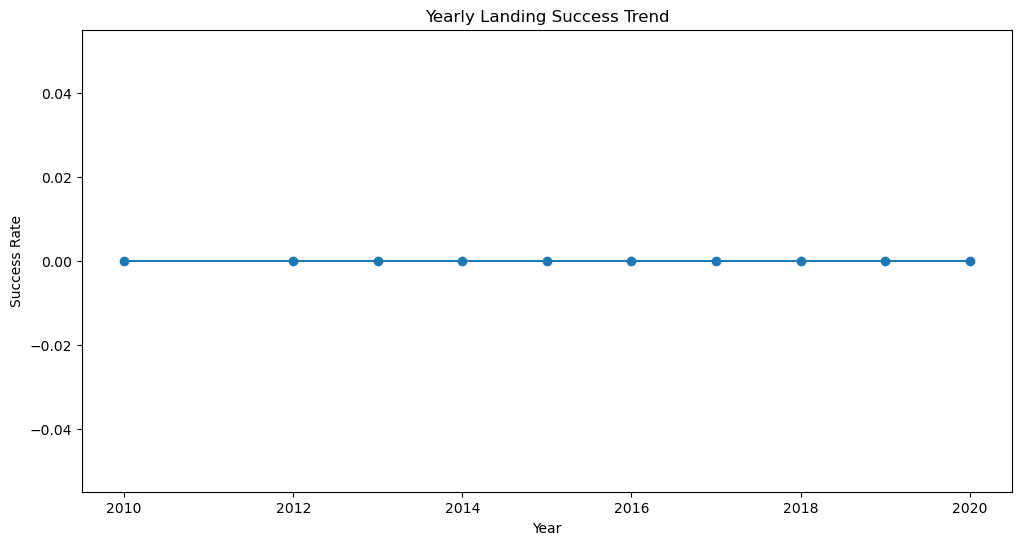

In [4]:
# 每年回收成功率变化趋势
df['Year'] = pd.to_datetime(df['Date'], errors='coerce').dt.year
year_success = df.groupby('Year')['Class'].mean()
year_success.plot(kind='line', marker='o')
plt.ylabel('Success Rate')
plt.title("Yearly Landing Success Trend")
plt.show()

In [5]:
import folium
from folium.plugins import MarkerCluster

# 以卡纳维拉尔角为中心
map1 = folium.Map(location=[28.5623, -80.5774], zoom_start=4)
marker_cluster = MarkerCluster().add_to(map1)

for idx, row in df.iterrows():
    # 跳过经纬度为空的行
    if pd.notna(row['Latitude']) and pd.notna(row['Longitude']):
        popup_text = f"Site: {row['LaunchSite']}<br>Success: {row['Class']}"
        folium.Marker(
            location=[row['Latitude'], row['Longitude']],
            popup=popup_text
        ).add_to(marker_cluster)

map1